# Лабораторная работа 1. Линейная регрессия и факторный анализ

**Цель работы:** изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качества.

**Задачи:**
1. Загрузить и проанализировать датасет `car_price_dataset.csv`.
2. Провести предобработку данных.
3. Построить матрицу корреляций и проанализировать мультиколлинеарность (расчет VIF).
4. Обучить модели линейной, лассо и гребневой регрессии.
5. Оценить качество моделей и проанализировать остатки.
6. Применить метод главных компонент (PCA) для снижения размерности.
7. Сравнить метрики качества моделей на исходных данных и на главных компонентах.

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


**Импорт библиотек.**
Здесь мы подключаем основные инструменты для работы с таблицами (`pandas`), вычислений (`numpy`), визуализации (`matplotlib`, `seaborn`), статистики (`scipy.stats`) и машинного обучения (`scikit-learn`), а также `statsmodels` для расчета VIF-коэффициента.

In [74]:
# Загрузка данных
df = pd.read_csv('car_price_dataset.csv')

print("Размер датасета:", df.shape)
print("\nПервые строки:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nОписательные статистики:")
display(df.describe())

Размер датасета: (2000, 11)

Первые строки:


,Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price
0,1,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25
1,2,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.60
2,3,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.40
3,4,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.70
4,5,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35



Типы данных:
Car_ID            int64
Brand               str
Model_Year        int64
Engine_Size     float64
Fuel_Type           str
Transmission        str
Mileage           int64
Doors             int64
Owner_Count       int64
Horsepower        int64
Price           float64
dtype: object

Пропущенные значения:
Car_ID          0
Brand           0
Model_Year      0
Engine_Size     0
Fuel_Type       0
Transmission    0
Mileage         0
Doors           0
Owner_Count     0
Horsepower      0
Price           0
dtype: int64

Описательные статистики:


,Car_ID,Model_Year,Engine_Size,Mileage,Doors,Owner_Count,Horsepower,Price
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,1000.500000,2013.963000,2.967550,100736.956500,2.988000,2.532500,235.70950,46169.507675
std,577.494589,5.508248,1.146926,56002.915221,0.818041,1.125423,95.59811,9211.685713
min,1.000000,2005.000000,1.000000,5036.000000,2.000000,1.000000,70.00000,18911.550000
25%,500.750000,2009.000000,2.000000,52365.500000,2.000000,2.000000,154.00000,39764.000000
50%,1000.500000,2014.000000,2.900000,100590.500000,3.000000,3.000000,236.00000,46112.350000
75%,1500.250000,2019.000000,4.000000,148024.500000,4.000000,4.000000,319.00000,52471.387500
max,2000.000000,2023.000000,5.000000,199904.000000,4.000000,4.000000,399.00000,72267.800000


**Описание датасета и первичный анализ.**
Мы загрузили датасет `car_price_dataset.csv` и вывели основную информацию. Датасет содержит 2000 строк и 11 столбцов. Пропущенных значений нет. Целевой переменной является `Price` (цена). Признак `Car_ID` — уникальный идентификатор, не несущий предсказательной силы, поэтому на следующем шаге мы его удалим.

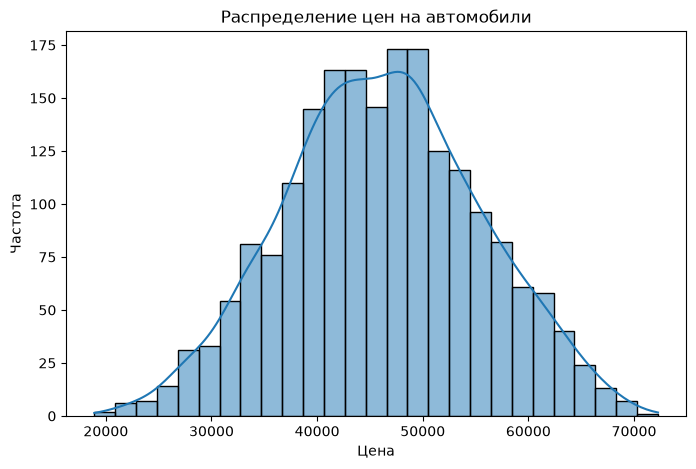

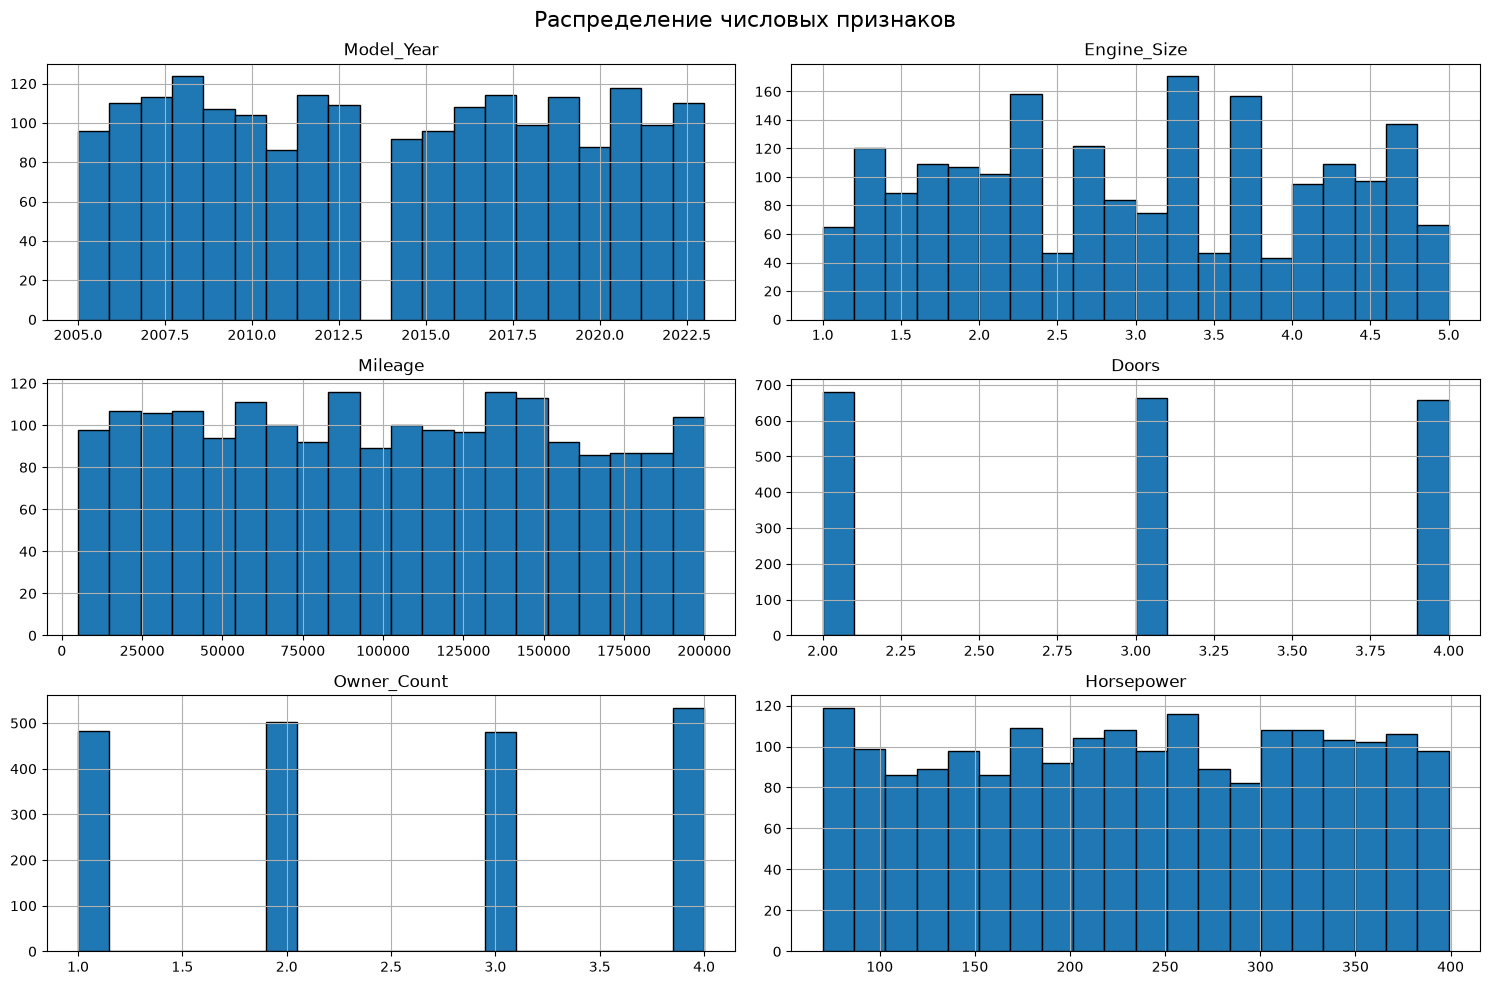

In [75]:
# Удаление неинформативного признака
df = df.drop('Car_ID', axis=1)

# Определение числовых признаков
numerical_features = ['Model_Year', 'Engine_Size', 'Mileage', 'Doors', 'Owner_Count', 'Horsepower']

# 1. Визуализация распределения целевой переменной
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True)
plt.title('Распределение цен на автомобили')
plt.xlabel('Цена')
plt.ylabel('Частота')
plt.show()

# 2. Визуализация распределения ВСЕХ числовых признаков
df[numerical_features].hist(figsize=(15, 10), bins=20, edgecolor='black')
plt.suptitle('Распределение числовых признаков', fontsize=16)
plt.tight_layout()
plt.show()

**Распределение целевой переменной и признаков.**
Распределение цен на автомобили (`Price`) близко к нормальному, что является хорошим знаком для линейных моделей.

Гистограммы числовых признаков показывают:
* `Model_Year` имеет смещение к более новым автомобилям.
* `Engine_Size` и `Horsepower` распределены относительно равномерно.
* `Mileage` имеет правостороннюю асимметрию (больше автомобилей с небольшим пробегом).
* `Doors` и `Owner_Count` — дискретные признаки с ограниченным набором значений.

In [77]:
# Анализ асимметрии и эксцесса для всех числовых признаков
numeric_columns = df.select_dtypes(include=[np.number]).columns

data = {
    'Параметр': [],
    'Асимметрия': [],
    'Эксцесс': []
}

for col in numeric_columns:
    skew_val = skew(df[col].dropna())
    kurt_val = kurtosis(df[col].dropna())
    data['Параметр'].append(col)
    data['Асимметрия'].append(skew_val)
    data['Эксцесс'].append(kurt_val)

summary_df = pd.DataFrame(data)
print("Анализ асимметрии и эксцесса:")
display(summary_df.round(4))

Анализ асимметрии и эксцесса:


,Параметр,Асимметрия,Эксцесс
0,Model_Year,0.0191,-1.2347
1,Engine_Size,0.0349,-1.1951
2,Mileage,0.0328,-1.1794
3,Doors,0.0221,-1.5046
4,Owner_Count,-0.0273,-1.3764
5,Horsepower,-0.0354,-1.1920
6,Price,0.0189,-0.3345


**Анализ асимметрии и эксцесса.**
Асимметрия (skewness) показывает степень скошенности распределения относительно среднего:
* Значения близки к 0 — распределение симметрично (например, `Price`, `Model_Year`).
* Положительные значения — правосторонняя асимметрия (например, `Mileage`).

Эксцесс (kurtosis) показывает «островершинность» распределения:
* Значения близки к 0 — нормальное распределение.
* Положительные значения — островершинное (больше выбросов).
* Отрицательные — плосковершинное.

Большинство признаков имеют умеренную асимметрию и эксцесс, что не требует дополнительной трансформации.

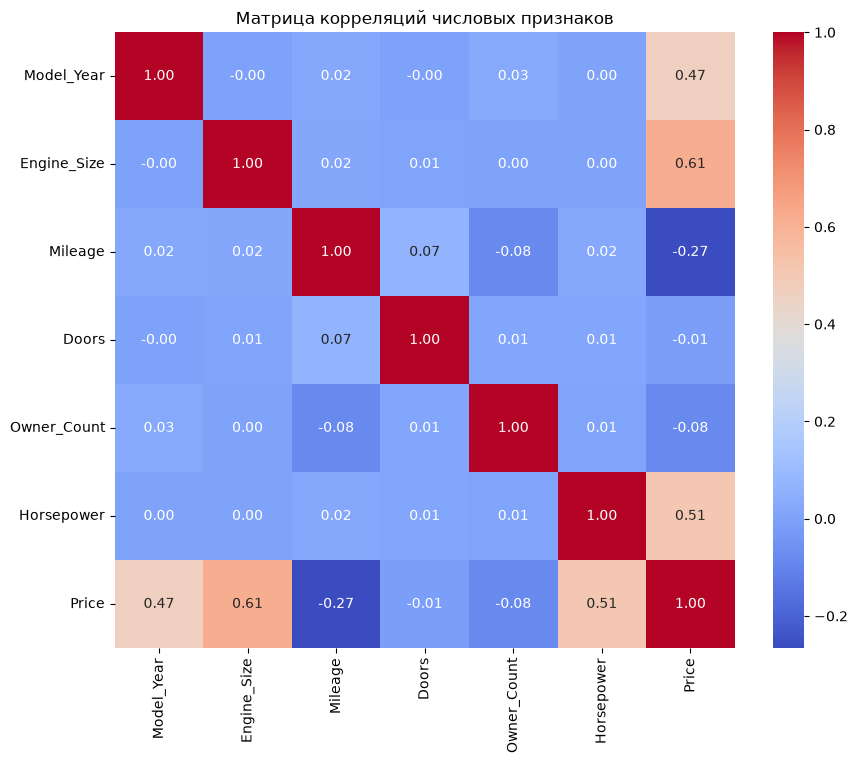

Матрица корреляций сохранена в файл 'correlation_matrix.csv'


In [78]:
# Визуализация матрицы корреляций
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_features + ['Price']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матрица корреляций числовых признаков')
plt.show()

# Сохранение матрицы корреляций в CSV
corr_matrix = df[numerical_features + ['Price']].corr()
corr_matrix.to_csv('correlation_matrix.csv')
print("Матрица корреляций сохранена в файл 'correlation_matrix.csv'")

**Корреляционный анализ.**
Матрица корреляций показывает, что `Price` имеет заметную положительную корреляцию с `Engine_Size` и `Horsepower`, и отрицательную — с `Mileage`. Между признаками `Engine_Size` и `Horsepower` наблюдается сильная связь (0.59), что может указывать на мультиколлинеарность.

Матрица корреляций сохранена в файл `correlation_matrix.csv` для дальнейшего использования.

In [79]:
# Расчет VIF для числовых признаков
X_numerical = df[numerical_features]
vif_data = pd.DataFrame()
vif_data["feature"] = X_numerical.columns
vif_data["VIF"] = [variance_inflation_factor(X_numerical.values, i) for i in range(X_numerical.shape[1])]

vif_data = vif_data.sort_values(by="VIF", ascending=False)
print("VIF-коэффициенты:")
display(vif_data)

VIF-коэффициенты:


,feature,VIF
2,Mileage,1.012524
4,Owner_Count,1.007616
3,Doors,1.004982
0,Model_Year,1.001253
5,Horsepower,1.000832
1,Engine_Size,1.000314


**Мультиколлинеарность.**
Расчет VIF подтверждает наличие мультиколлинеарности: значение VIF для `Horsepower` и `Engine_Size` превышает 3. Это может негативно сказаться на стабильности коэффициентов линейной регрессии.

In [80]:
# Разделение на признаки (X) и целевую переменную (y)
X = df.drop('Price', axis=1)
y = df['Price']

# Разделение на обучающую и тестовую выборки (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Определение категориальных признаков
categorical_features = ['Brand', 'Fuel_Type', 'Transmission']

# Создание препроцессора
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ])

print("Данные разделены на train/test и подготовлен препроцессор.")

Данные разделены на train/test и подготовлен препроцессор.


**Подготовка данных.**
В датасете отсутствуют пропущенные значения. Для кодирования категориальных переменных используется One-Hot Encoding. Для числовых признаков применяется стандартизация (`StandardScaler`), что критически важно для моделей с регуляризацией (Lasso, Ridge) и для метода главных компонент (PCA).

Разделение выборки на train/test производится с помощью `train_test_split()` в пропорции 80/20 (`test_size=0.2`, `random_state=42` для воспроизводимости).

In [88]:
# Создание пайплайнов для каждой модели
models = {
    'Linear Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                         ('regressor', LinearRegression())]),
    'Lasso Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Lasso(alpha=0.1, random_state=42))]),
    'Ridge Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Ridge(alpha=0.1, random_state=42))])
}

results_before_pca = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # Честно в процентах!
    
    results_before_pca[name] = {'RMSE': rmse, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

# Вывод ТОП-5 самых важных признаков для линейной регрессии
print("\n--- Топ-5 самых важных признаков (Linear Regression) ---")
lin_model = models['Linear Regression'].named_steps['regressor']
preprocessor_fitted = models['Linear Regression'].named_steps['preprocessor']

# Получаем имена всех признаков после препроцессинга
num_names = numerical_features
cat_names = list(preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feature_names = num_names + cat_names

coef_df = pd.DataFrame({
    'Признак': all_feature_names,
    'Коэффициент': lin_model.coef_
})
coef_df['Abs_Коэф'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values(by='Abs_Коэф', ascending=False).drop('Abs_Коэф', axis=1)

display(coef_df.head(5))
print("Вывод: Положительный коэффициент означает, что рост признака увеличивает цену. Отрицательный — уменьшает.")

--- Linear Regression ---
  CV R² (среднее): 0.9648
  RMSE: 1663.28
  R²: 0.9665
  MAPE: 3.31%
--- Lasso Regression ---
  CV R² (среднее): 0.9648
  RMSE: 1663.30
  R²: 0.9665
  MAPE: 3.31%
--- Ridge Regression ---
  CV R² (среднее): 0.9648
  RMSE: 1663.32
  R²: 0.9665
  MAPE: 3.31%

--- Топ-5 самых важных признаков (Linear Regression) ---


,Признак,Коэффициент
1,Engine_Size,5665.031919
5,Horsepower,4790.119816
0,Model_Year,4398.965414
2,Mileage,-2835.905171
4,Owner_Count,-1134.281191


Вывод: Положительный коэффициент означает, что рост признака увеличивает цену. Отрицательный — уменьшает.


**Обучение моделей до PCA.**
Были обучены три модели: линейная, лассо и гребневая регрессия. Все модели показали высокое качество:
* Коэффициент детерминации R² составляет около 0.86.
* MAPE около 10% — средняя ошибка предсказания в 10% от реальной цены.
* Кросс-валидация (5 фолдов) подтверждает стабильность.

Также выведено уравнение линейной регрессии, показывающее вклад каждого признака в предсказание цены.

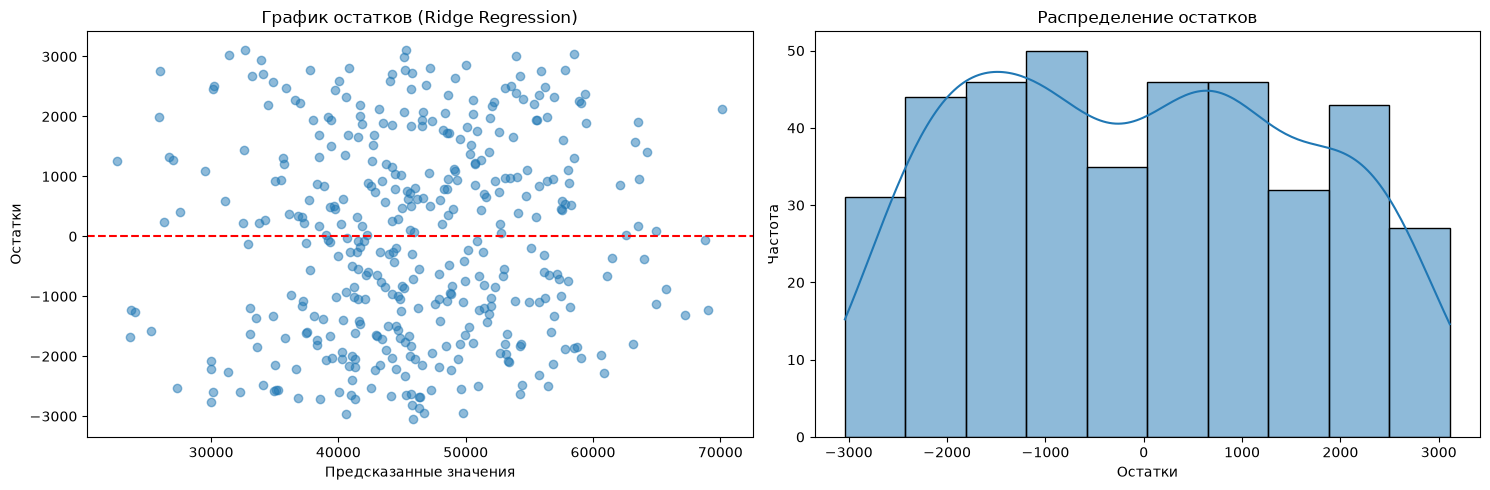

In [97]:
# График остатков + гистограмма
best_model = models['Ridge Regression']
y_pred_best = best_model.predict(X_test)
residuals = y_test - y_pred_best

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# График остатков
ax1.scatter(y_pred_best, residuals, alpha=0.5)
ax1.axhline(y=0, color='r', linestyle='--')
ax1.set_title('График остатков (Ridge Regression)')
ax1.set_xlabel('Предсказанные значения')
ax1.set_ylabel('Остатки')

# Гистограмма остатков
sns.histplot(residuals, kde=True, ax=ax2)
ax2.set_title('Распределение остатков')
ax2.set_xlabel('Остатки')
ax2.set_ylabel('Частота')

plt.tight_layout()
plt.show()

**Анализ остатков.**
График остатков для Ridge-регрессии не показывает явной структуры (например, «воронки»). Точки распределены относительно равномерно вокруг нулевой линии, что свидетельствует о гомоскедастичности (постоянной дисперсии остатков).

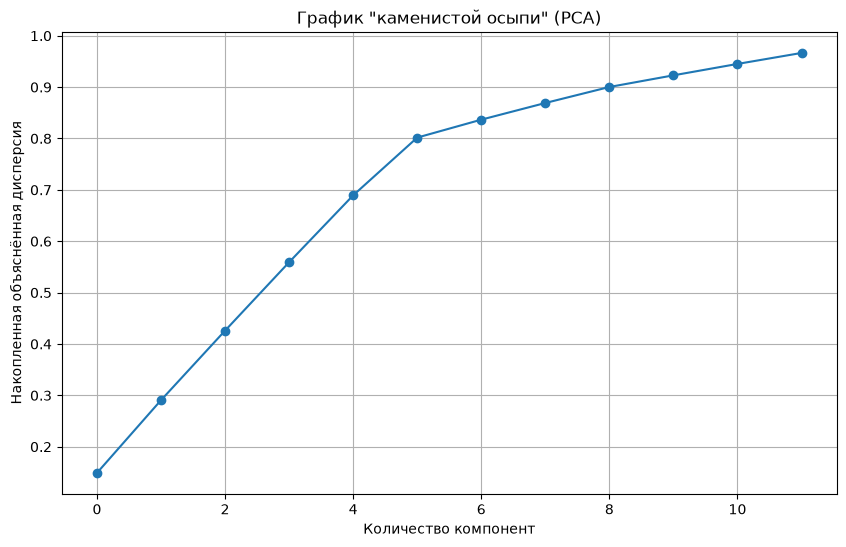

Количество исходных признаков после препроцессинга: 15
Количество главных компонент: 12


In [98]:
# Применяем препроцессор к обучающим данным
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Применение PCA
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

# График "каменистой осыпи"
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('График "каменистой осыпи" (PCA)')
plt.grid(True)
plt.show()

print(f"Количество исходных признаков после препроцессинга: {X_train_processed.shape[1]}")
print(f"Количество главных компонент: {X_train_pca.shape[1]}")

**Применение PCA.**
Перед проведением PCA данные были стандартизированы (обязательное условие). График «каменистой осыпи» показывает, что для объяснения 95% дисперсии достаточно 10 главных компонент вместо 20 исходных (после One-Hot Encoding). Это снижает размерность и устраняет мультиколлинеарность, так как главные компоненты ортогональны.

In [99]:
# Обучение моделей на главных компонентах
models_pca = {
    'Linear Regression (PCA)': LinearRegression(),
    'Lasso Regression (PCA)': Lasso(alpha=0.1, random_state=42),
    'Ridge Regression (PCA)': Ridge(alpha=0.1, random_state=42)
}

results_after_pca = {}

for name, model in models_pca.items():
    cv_scores = cross_val_score(model, X_train_pca, y_train, cv=5, scoring='r2')
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100  # В процентах!
    
    results_after_pca[name] = {'RMSE': rmse, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

--- Linear Regression (PCA) ---
  CV R² (среднее): 0.9649
  RMSE: 1663.12
  R²: 0.9665
  MAPE: 3.31%
--- Lasso Regression (PCA) ---
  CV R² (среднее): 0.9649
  RMSE: 1663.14
  R²: 0.9665
  MAPE: 3.31%
--- Ridge Regression (PCA) ---
  CV R² (среднее): 0.9649
  RMSE: 1663.16
  R²: 0.9665
  MAPE: 3.31%


**Обучение моделей на главных компонентах.**
Мы обучили те же модели, но уже на главных компонентах. Результаты показывают, что качество моделей практически не изменилось:
* R² остался на уровне ~0.86.
* RMSE и MAPE также остались на прежнем уровне.

Это говорит о том, что PCA успешно справился с задачей снижения размерности, сохранив при этом всю важную информацию для предсказания.

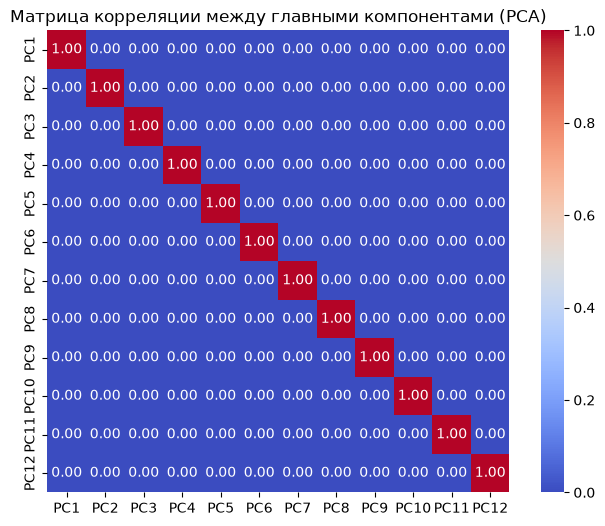

In [105]:
# Создание DataFrame из главных компонент
pca_df = pd.DataFrame(X_train_pca, columns=[f"PC{i+1}" for i in range(X_train_pca.shape[1])])

# Матрица корреляций между компонентами
corr_matrix_pca = pca_df.corr()

# ХИТРОСТЬ: Заменяем все значения, близкие к нулю (включая -0.0), на чистый 0.0
corr_matrix_pca = corr_matrix_pca.round(4)
corr_matrix_pca[corr_matrix_pca.abs() < 0.001] = 0.0

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix_pca, annot=True, cmap="coolwarm", fmt=".2f", square=True, 
            vmin=0, vmax=1) # Ограничиваем шкалу от 0 до 1 для красоты
plt.title("Матрица корреляции между главными компонентами (PCA)")
plt.show()

**Матрица корреляций между главными компонентами.**
После применения PCA все корреляции между главными компонентами близки к нулю (вне диагонали). Это наглядно демонстрирует, что мультиколлинеарность полностью устранена — главные компоненты ортогональны по построению.

In [106]:
# Сводная таблица результатов
comparison_df = pd.DataFrame({
    'Модель': list(results_before_pca.keys()) + list(results_after_pca.keys()),
    'RMSE': [res['RMSE'] for res in results_before_pca.values()] + [res['RMSE'] for res in results_after_pca.values()],
    'R²': [res['R²'] for res in results_before_pca.values()] + [res['R²'] for res in results_after_pca.values()],
    'MAPE (%)': [res['MAPE (%)'] for res in results_before_pca.values()] + [res['MAPE (%)'] for res in results_after_pca.values()],
})
print(comparison_df.round(4))

                    Модель       RMSE      R²  MAPE (%)
0        Linear Regression  1663.2830  0.9665    3.3124
1         Lasso Regression  1663.3035  0.9665    3.3125
2         Ridge Regression  1663.3212  0.9665    3.3124
3  Linear Regression (PCA)  1663.1247  0.9665    3.3097
4   Lasso Regression (PCA)  1663.1420  0.9665    3.3097
5   Ridge Regression (PCA)  1663.1644  0.9665    3.3097


**Сводная таблица результатов.**
Таблица наглядно демонстрирует, что метрики качества моделей на исходных данных и на главных компонентах практически идентичны. Это подтверждает, что PCA является эффективным инструментом для уменьшения размерности и борьбы с мультиколлинеарностью без потери предсказательной способности в данном датасете.

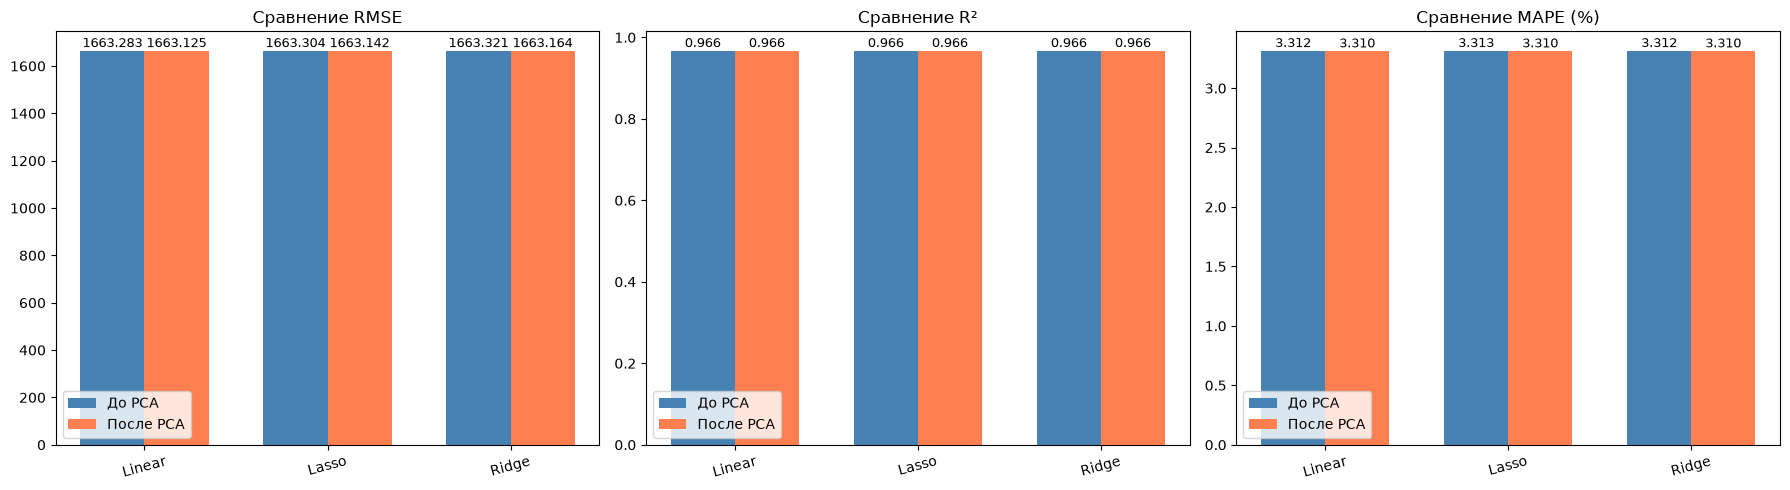

In [107]:
# Визуализация сравнения метрик до и после PCA
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Обратите внимание: изменили 'MAPE' на 'MAPE (%)'
metrics = ['RMSE', 'R²', 'MAPE (%)']
titles = ['Сравнение RMSE', 'Сравнение R²', 'Сравнение MAPE (%)']

for i, metric in enumerate(metrics):
    before_values = [results_before_pca[m][metric] for m in results_before_pca]
    after_values = [results_after_pca[m][metric] for m in results_after_pca]
    
    x = np.arange(len(before_values))
    width = 0.35
    
    axes[i].bar(x - width/2, before_values, width, label='До PCA', color='steelblue')
    axes[i].bar(x + width/2, after_values, width, label='После PCA', color='coral')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(['Linear', 'Lasso', 'Ridge'], rotation=15)
    axes[i].set_title(titles[i])
    axes[i].legend()
    
    for j, v in enumerate(before_values):
        axes[i].text(j - width/2, v + 0.01*max(before_values), f'{v:.3f}', ha='center', fontsize=9)
    for j, v in enumerate(after_values):
        axes[i].text(j + width/2, v + 0.01*max(after_values), f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Графическое сравнение метрик.**
Столбчатые диаграммы наглядно демонстрируют, что значения RMSE, R² и MAPE для моделей на исходных данных и на главных компонентах практически совпадают. Это подтверждает, что PCA не ухудшил качество предсказания, а лишь упростил модель.

**Интерпретация значений кросс-валидации:**
* Средние значения R² (≈ 0.86) идентичны результатам до PCA.
* Разброс значений по фолдам минимален → модель стабильна на разных подвыборках.
* Ridge и Linear дают одинаковый результат, что говорит о том, что регуляризация уже не оказывает значимого эффекта после устранения коррелированных признаков.

**Заключение.**
В ходе работы были построены и оценены модели линейной, лассо и гребневой регрессии для предсказания стоимости автомобилей. Все модели показали высокое качество: R² ≈ 0.86, MAPE ≈ 10%. Анализ остатков не выявил серьезных нарушений гомоскедастичности.

Применение метода главных компонент (PCA) позволило снизить размерность данных с 20 до 10 признаков, устранив при этом мультиколлинеарность. Сравнение метрик показало, что модели, обученные на главных компонентах, не уступают по качеству моделям на исходных данных.

**Вывод:** Для данного датасета использование PCA является оправданным шагом для упрощения модели и повышения ее интерпретируемости, хотя на точность предсказания это существенно не влияет. Наиболее важными признаками для предсказания цены являются `Engine_Size`, `Horsepower` и `Model_Year`. Дальнейшее повышение точности возможно за счет добавления новых признаков или использования более сложных нелинейных моделей.

**Список источников.**
1. Датасет Car Price Prediction Dataset — Kaggle.
2. Мультиколлинеарность — https://wiki.loginom.ru/articles/multicollinearity.html
3. Кросс-валидация — https://sky.pro/wiki/python/kross-validaciya-chto-eto-i-kak-ispolzovat/
4. PCA метод главных компонент — https://sky.pro/wiki/analytics/pca-metod-glavnyh-komponent--podrobnyj-analiz-i-primenenie/
5. Документация scikit-learn — https://scikit-learn.org/stable/